In [1]:
import torch
import random
import tqdm

In [2]:
import numpy as np
import pandas as pd
import prior as pr
import matplotlib.pyplot as plt

In [3]:
from pymfe.mfe import MFE
from joblib import Parallel, delayed
from multiprocessing import Pool

In [4]:
N_DATASETS = 1000
SEED = 11
BATCH_SIZE = 1
N_JOBS = 8

In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [6]:
device = 'cuda' if torch.accelerator.is_available() else 'cpu'
device

'cuda'

In [7]:
prior = pr.ModdedNanoPrior(pr.PriorConfig(), device)

In [8]:
data = []
for _ in range(N_DATASETS):
    X_train, y_train, X_test, y_test = prior.batch(BATCH_SIZE)
    X = torch.cat([X_train, X_test], dim=1)[0].cpu().numpy()
    y = torch.cat([y_train, y_test], dim=1)[0].long().cpu().numpy()
    data.append((X, y))

In [9]:
def extract(args):
    i, X, y = args
    mfe = MFE(groups='complexity', features='all', summary='mean', random_state=SEED)
    mfe.fit(X, y, suppress_warnings=True)
    measures, values = mfe.extract(suppress_warnings=True)
    return {'id': i, 'n_classes': len(np.unique(y)), 'n_rows': X.shape[0], 'n_cols': X.shape[1], **dict(zip(measures, map(float, values)))}

In [10]:
data_tuples = [(i, X, y) for i, (X, y) in enumerate(data)]

In [11]:
with Pool(N_JOBS) as pool:   
    complexity = list(tqdm.tqdm(pool.imap(extract, data_tuples), total=len(data_tuples)))

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [33:25<00:00,  2.01s/it]


In [12]:
df = pd.DataFrame(complexity)
df

,id,n_classes,n_rows,n_cols,c1,c2,cls_coef,density,f1.mean,f1v.mean,...,l3.mean,lsc,n1,n2.mean,n3.mean,n4.mean,t1,t2,t3,t4
0,0,7,8159,18,1.000000,3.505049e-08,0.161021,0.945383,0.815851,NaN,...,0.062388,0.999603,0.600319,0.491369,0.452874,0.687462,0.934918,0.002206,0.000613,0.277778
1,1,8,9319,13,1.000000,1.315871e-08,0.128660,0.941743,0.607596,NaN,...,0.043105,0.995511,0.527846,0.447348,0.407125,0.680116,0.760275,0.001395,0.000537,0.384615
2,2,7,4902,18,1.000000,8.092695e-08,0.213716,0.950855,0.843235,NaN,...,0.180996,0.999473,0.630355,0.493380,0.448796,0.669727,0.955732,0.003672,0.001224,0.333333
3,3,3,6254,12,1.000000,3.834783e-08,0.260012,0.871258,0.770620,NaN,...,0.062763,0.976219,0.159098,0.334874,0.106012,0.395427,0.333706,0.001919,0.000799,0.416667
4,4,8,9513,7,1.000000,1.262979e-08,0.164137,0.942952,0.561752,NaN,...,0.103679,0.996173,0.555240,0.460515,0.412804,0.677914,0.769894,0.000736,0.000315,0.428571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,2,3575,9,1.000000,1.564869e-07,0.279341,0.861556,0.881446,NaN,...,0.006993,0.957585,0.060140,0.245246,0.037203,0.300979,0.116643,0.002517,0.001399,0.555556
996,996,5,6215,16,1.000000,0.000000e+00,0.251576,0.893640,0.471105,NaN,...,0.048190,0.999210,0.458246,0.469140,0.323411,0.477393,0.837490,0.002574,0.000965,0.375000
997,997,3,5571,13,1.000000,0.000000e+00,0.255679,0.857327,0.478815,NaN,...,0.038682,0.953701,0.241429,0.372512,0.168192,0.393287,0.471370,0.002334,0.001077,0.461538
998,998,7,1444,16,0.999999,9.328487e-07,0.155295,0.900649,0.436750,NaN,...,0.003813,0.984958,0.263850,0.405684,0.173823,0.374654,0.612881,0.011080,0.005540,0.500000


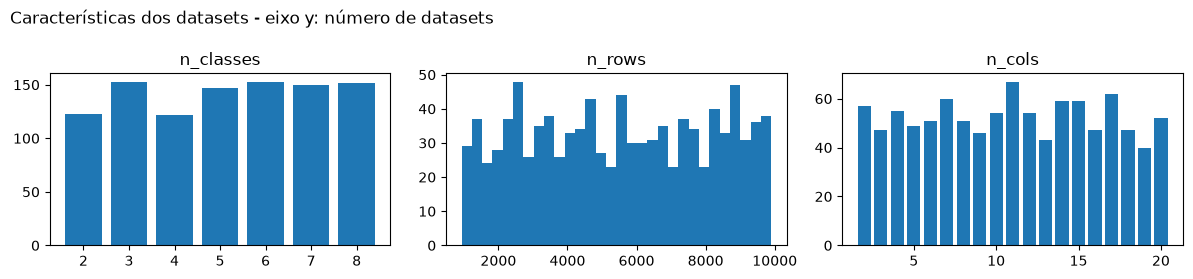

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, col in zip(axes, df.columns[1:4]):
    if col not in df:
        ax.set_visible(False); continue
    v = df[col]
    if v.nunique() <= 30:                                   # discreto: uma barra por valor
        cont = v.value_counts().sort_index()
        ax.bar(cont.index, cont.values, width=0.8)
    else:
        ax.hist(v, bins=30, linewidth=1)
    ax.set_title(col)
    ax.grid(axis="x", visible=False)
fig.suptitle("Características dos datasets - eixo y: número de datasets", x=0.01, ha="left")
fig.tight_layout(); plt.show()

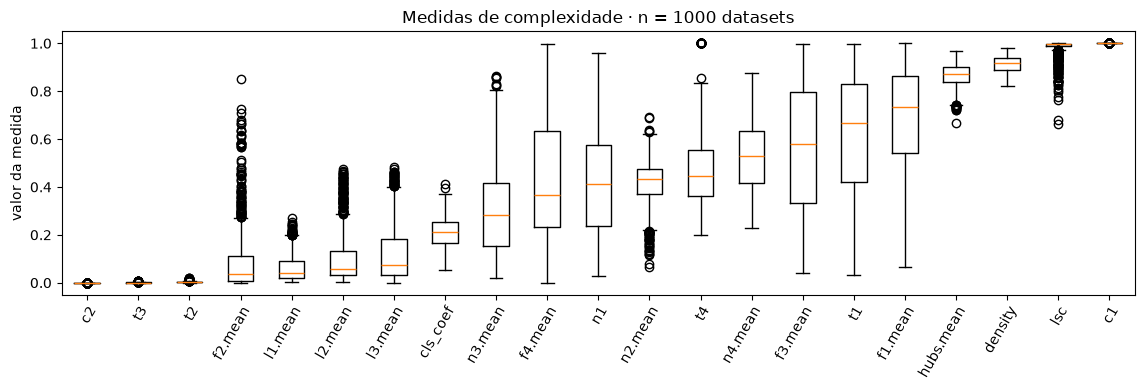

In [18]:
meta = ["id", "n_classes", "n_rows", "n_cols"]
medidas = df.drop(columns=meta).dropna(axis="columns", how="all")
variaveis = medidas.median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(variaveis)), 4))
ax.boxplot([medidas[c].dropna() for c in variaveis])
ax.set_xticks(
    range(1, len(variaveis) + 1), variaveis,
    rotation=60, ha="right", rotation_mode="anchor",
)
ax.set_ylabel("valor da medida")
ax.set_title(f"Medidas de complexidade · n = {len(df)} datasets")
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

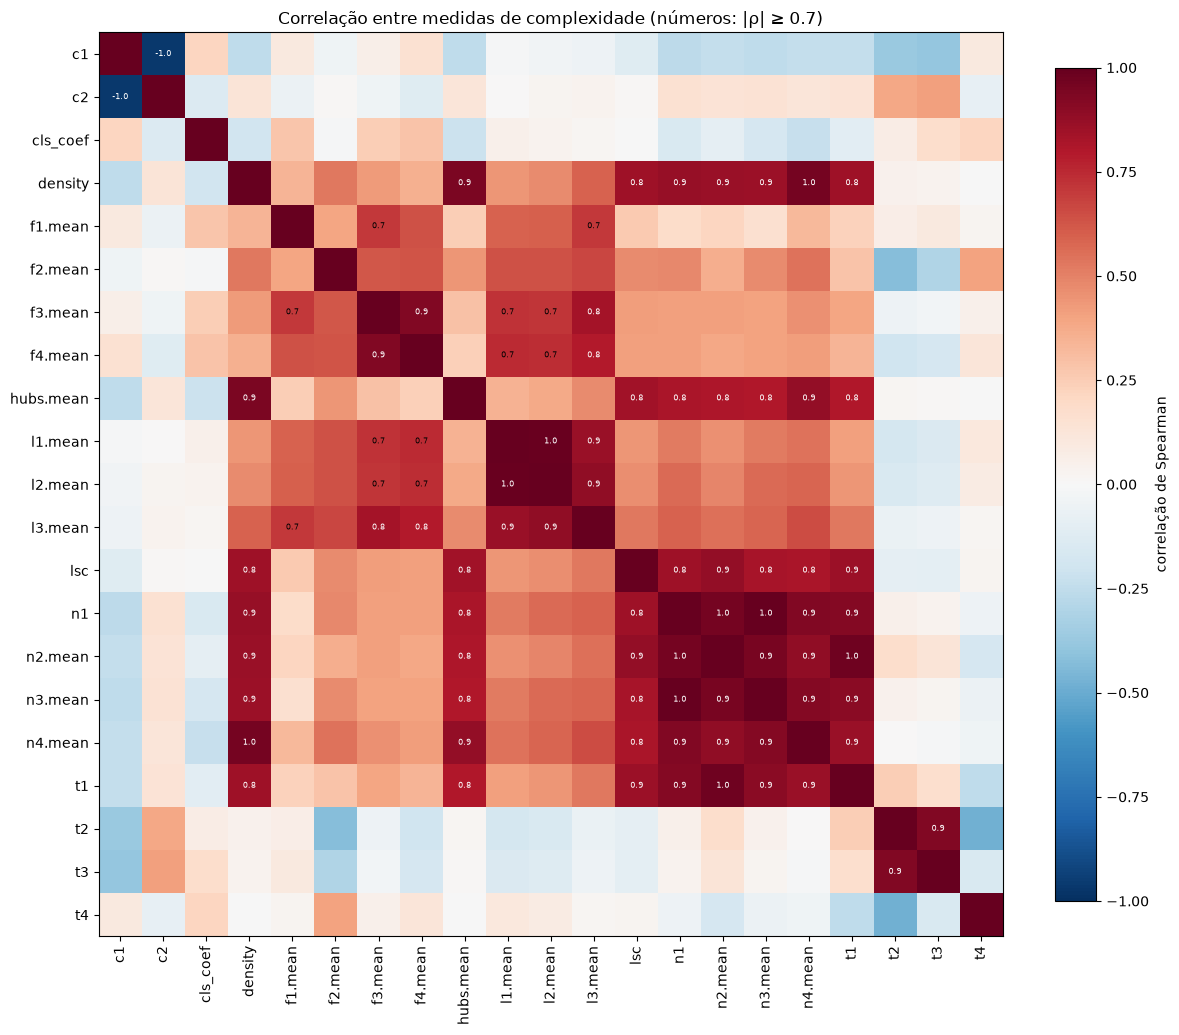

In [20]:
cols_corr = df.iloc[:, 4:].dropna(axis="columns", how="all").columns
corr = df[cols_corr].corr(method="spearman")
n = len(cols_corr)
fig, ax = plt.subplots(figsize=(0.45 * n + 2.5, 0.45 * n + 1))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)     # azul = negativa, vermelho = positiva
ax.set_xticks(range(n), cols_corr, rotation=90)
ax.set_yticks(range(n), cols_corr)
ax.grid(False)
for i in range(n):
    for j in range(n):
        r = corr.iloc[i, j]
        if i != j and abs(r) >= 0.7:                          # anota só as correlações fortes
            ax.text(j, i, f"{r:.1f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(r) > 0.75 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, label="correlação de Spearman")
ax.set_title("Correlação entre medidas de complexidade (números: |ρ| ≥ 0.7)")
fig.tight_layout(); plt.show()

In [ ]:
# Próximos passos
# - rodar na axia
# - usar o prior do tabicl
# - definir os hyperparametros de geração das bases
# - rodar as medias de complexidade para bases reais
# - vamos gerar dados siteticos?

# Mais comentarios
# - arvore - impureza de gini
# - 